# The cost of a trap array and its gradient: what an optimiser is given

**Question:** What number does a conjugate-gradient optimiser minimise for a trap array, can its analytic gradient be trusted, and what does the first descent look like next to a projection loop?

- Level: 1, fundamentals.
- Prerequisites: `03-gerchberg-saxton/02-weights-for-uniformity`, which introduces the weighted loop M06 and the three trap metrics.
- Reading time: about 20 minutes. The notebook runs in about a minute.

## Objectives

A Gerchberg-Saxton loop never states what it is minimising: it alternates two projections, and the quality of the array is whatever the loop happens to reach. An optimiser works the other way round. You write down the number that says how bad a hologram is, and the optimiser lowers it. This notebook writes that number for a trap array, checks the derivative that every gradient method of the topic relies on, and runs a first descent. By the end you can:

- write the cost of a trap array and say what each of its terms asks for;
- check an analytic gradient against finite differences and read the plot that shows whether it passes;
- run conjugate gradient from random phases and say what its descent looks like;
- say how the first descent compares with the weighted loop M06 at equal iterations.

The notebooks that follow build on it: `05-optimization/02-the-wirtinger-gradient-and-adams-step` changes the forward model, and the two level 3 notebooks of the topic compare the methods M10 and M11 with the classical loops.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw
from pipeline.model.holo.methods.optim import m10_cg
from pipeline.model.holo.methods.optim._common import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads one case of the example file `data/examples/cases.json`, written by the pipeline's case library and read back through the pipeline's own contract reader.

- Owner: this repository; the case is synthetic, defined by the calibration task of Di Leonardo, Ianni and Ruocco (2007).
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C12 (a 10 x 10 square array on a Gaussian beam).

In [2]:
# case C12 of the example file: the optical setup and the 100 traps of the 10 x 10 task
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "traps | SLM", setup.n_pix, "x", setup.n_pix, "pixels")
print("pitch", rec["setup"]["pitch_um"], "um | wavelength", rec["setup"]["wavelength_nm"], "nm")

C12_calibration | 100 traps | SLM 256 x 256 pixels
pitch 20 um | wavelength 850 nm


## Method

### Step 1: the cost and its gradient

With $V_m$ the field at trap $m$ and $I_m = |V_m|^2$ the fraction of the input power that reaches it, the cost of Harte et al. (2014, eqs 6 and 10) for point traps is

$$C_t(\phi) = \frac{\sum_m (I_m - s\,T_m)^t}{\sum_m (s\,T_m)^t}, \qquad T_m = \eta\,\frac{w_m}{\sum_k w_k},$$

where $w_m$ are the target weights, $\eta$ the efficiency the target is asked to have, $s$ a fixed scale (1 here) and $t$ an even power; $t = 2$ is the plain squared error. Two things are written into this one line that a projection loop leaves implicit. The sum of the targets is $\eta$, so the cost asks for a total power as well as for equal traps. And the denominator makes the value scale free.

The gradient with respect to every pixel phase follows from the chain rule through the Fourier transform. For a real loss $L(I)$ the Wirtinger gradient with respect to the complex field is $G = L'(I)\,V$ (Chakravarthula et al., 2019), and pulling it back through the adjoint of the propagation gives $\partial L / \partial \phi_j = 2\,\mathrm{Re}\,(i f_j\,\overline{(\mathrm{Op}^H G)_j})$, with $f_j = A_j e^{i\phi_j}$ the SLM field. In the pipeline the cost is the class `TrapCost`, a public class of the shared optimisation module, and `value_grad` returns the value and the full gradient, one number per pixel, from one forward and one adjoint transform.

The cell below builds the cost for the 10 x 10 task at a random phase pattern, and reads the slope of the cost along one random unit direction.

In [3]:
# the explicit cost of the task and its analytic gradient at a random phase pattern
cost = TrapCost(setup, target.traps, None, t=2, efficiency=0.9)
rng = Rng(5)
phi0 = rng.phases(setup.n_pix**2).reshape(setup.n_pix, setup.n_pix)
value, grad, _ = cost.value_grad(phi0)
direction = rng.normal_array(setup.n_pix**2).reshape(phi0.shape)
direction /= np.linalg.norm(direction)
slope = float(np.sum(grad * direction))
print(f"cost at the random phase: {value:.6f}")
print(f"analytic slope along a random unit direction: {slope:.6e}")

cost at the random phase: 0.996880
analytic slope along a random unit direction: -2.124944e-08


An analytic gradient is only as good as its derivation, so it is checked before it is trusted. A central difference $(C(\phi + h d) - C(\phi - h d)) / 2h$ along the same direction $d$ must reproduce the analytic slope $g \cdot d$. The step $h$ has a window: too large and the difference misses the curvature of the cost, too small and the subtraction of two nearly equal costs loses digits. The cell sweeps $h$ over six decades.

In [4]:
# central differences of the same cost along the same direction, steps from 1e-1 down to 1e-6
steps = 10.0 ** -np.arange(1, 7)
rel_err = []
for h in steps:
    up = cost.value_grad(phi0 + h * direction)[0]
    down = cost.value_grad(phi0 - h * direction)[0]
    rel_err.append(abs((up - down) / (2 * h) - slope) / abs(slope))
for h, err in zip(steps, rel_err):
    print(f"step {h:.0e}: relative error of the slope {err:.2e}")

step 1e-01: relative error of the slope 1.24e-05
step 1e-02: relative error of the slope 5.80e-07
step 1e-03: relative error of the slope 8.04e-06
step 1e-04: relative error of the slope 3.68e-05
step 1e-05: relative error of the slope 2.72e-04
step 1e-06: relative error of the slope 2.08e-03


The printed errors are easier to read as a curve of error against step.

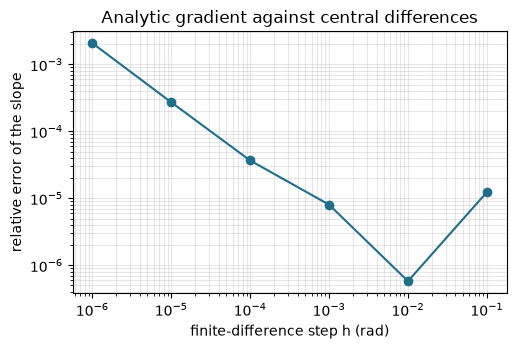

In [5]:
# the error of the finite-difference slope against the step size
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.loglog(steps, rel_err, "o-", color="#1f6f8b")
ax.set_xlabel("finite-difference step h (rad)")
ax.set_ylabel("relative error of the slope")
ax.set_title("Analytic gradient against central differences")
ax.grid(True, which="both", alpha=0.3)
plt.show()

The curve is a V. On the right the error falls as the step shrinks, because the truncation error of a central difference scales with $h^2$; on the left it rises again as $1/h$, which is the loss of digits in the subtraction. The minimum, near $h = 10^{-2}$ rad, is a relative error of $5.8 \times 10^{-7}$: the analytic gradient agrees with the numerical slope to six digits, so the derivation and its implementation are right. The plot does not say that the gradient is right at every pixel, only along this direction at this phase pattern; the pipeline's own tests repeat the check on trap and shaped targets, and a check along a handful of random directions is the usual standard. It also tells you the step to use if you ever check a gradient of your own: not the smallest one, but one in the middle of the V.

### Step 2: a first descent

M10 runs Fletcher-Reeves conjugate gradient with a strong-Wolfe line search on this cost, starting from random phases drawn through the seeded generator. The registry's default budget is 30 iterations, so the first cell runs that, and prints where the descent stands.

In [6]:
# the same cost at the registry's default budget: conjugate gradient for 30 iterations from random phases
res_cg30 = m10_cg.run(setup, target, budget=Budget(30), rng=Rng(1))
last = res_cg30.history[-1]
print(f"after 30 iterations: cost {last['cost']:.4f}  efficiency {last['efficiency']:.3f}  "
      f"rel. std {last['rel_std']:.2f} %")

after 30 iterations: cost 0.4906  efficiency 0.278  rel. std 37.27 %


After 30 iterations the cost is still 0.49 and the array is far from equal, so the budget that suits weighted GS does not suit this method. The cell runs 300 iterations with a line search of a few evaluations each, and prints the cost, the efficiency and the relative standard deviation of $I_m / w_m$ at six of them.

In [7]:
# conjugate gradient on the cost: 300 iterations from a random phase, efficiency target 0.9
res_cg = m10_cg.run(setup, target, budget=Budget(300), rng=Rng(1))
cg = res_cg.history
costs = np.array([h["cost"] for h in cg])
for k in (0, 9, 49, 99, 199, 299):
    h = cg[k]
    print(f"iteration {h['iteration']:3d}: cost {h['cost']:.4f}  "
          f"efficiency {h['efficiency']:.3f}  rel. std {h['rel_std']:.2f} %")
print(f"largest change of the cost between two iterations: {np.max(np.diff(costs)):.2e}")

iteration   1: cost 0.7220  efficiency 0.148  rel. std 93.73 %
iteration  10: cost 0.6180  efficiency 0.202  rel. std 57.55 %
iteration  50: cost 0.4062  efficiency 0.333  rel. std 26.87 %
iteration 100: cost 0.2618  efficiency 0.442  rel. std 11.50 %
iteration 200: cost 0.0950  efficiency 0.624  rel. std 5.10 %
iteration 300: cost 0.0222  efficiency 0.767  rel. std 2.08 %
largest change of the cost between two iterations: -3.06e-04


The cost fell at every step: the largest change between two consecutive iterations is negative, so it never rose. That is the first thing an explicit cost buys, a descent you can monitor. The relative standard deviation, however, is still 2 percent after 300 iterations, and the efficiency is climbing. For scale, run the weighted Gerchberg-Saxton loop M06 (Di Leonardo et al., 2007) on the same task from the same seed for 100 iterations, and score its final phase with the cost above, so that both methods are judged by the same number.

In [8]:
# weighted Gerchberg-Saxton on the same task and seed, 100 iterations, scored with the same cost
res_gsw = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
gsw = res_gsw.history
for k in (0, 9, 29, 99):
    h = gsw[k]
    print(f"iteration {h['iteration']:3d}: efficiency {h['efficiency']:.3f}  "
          f"rel. std {h['rel_std']:.2f} %")
print(f"cost of the weighted-GS phase after 100 iterations: {cost.value_grad(res_gsw.phi)[0]:.4f}")
print(f"cost of the CG phase after 300 iterations: {cost.value_grad(res_cg.phi)[0]:.4f}")

iteration   1: efficiency 0.755  rel. std 26.15 %
iteration  10: efficiency 0.789  rel. std 4.23 %
iteration  30: efficiency 0.797  rel. std 0.92 %
iteration 100: efficiency 0.807  rel. std 0.24 %
cost of the weighted-GS phase after 100 iterations: 0.0107
cost of the CG phase after 300 iterations: 0.0222


Both histories are plotted against the iteration. The iteration is the budget unit of the registry, but it is not the same amount of work for the two methods: a CG iteration includes a line search with several evaluations of the cost, a weighted-GS iteration is one forward and one backward transform.

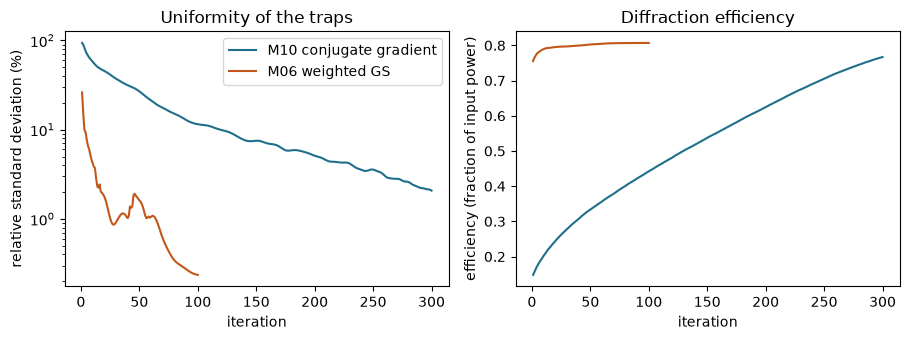

In [9]:
# relative standard deviation and efficiency of both methods against the iteration
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.5))
its_cg, its_gsw = [h["iteration"] for h in cg], [h["iteration"] for h in gsw]
a.semilogy(its_cg, [h["rel_std"] for h in cg], color="#1f6f8b", label="M10 conjugate gradient")
a.semilogy(its_gsw, [h["rel_std"] for h in gsw], color="#c2571a", label="M06 weighted GS")
a.set_xlabel("iteration")
a.set_ylabel("relative standard deviation (%)")
a.set_title("Uniformity of the traps")
a.legend()
b.plot(its_cg, [h["efficiency"] for h in cg], color="#1f6f8b")
b.plot(its_gsw, [h["efficiency"] for h in gsw], color="#c2571a")
b.set_xlabel("iteration")
b.set_ylabel("efficiency (fraction of input power)")
b.set_title("Diffraction efficiency")
plt.tight_layout()
plt.show()

On uniformity the loops of the Gerchberg-Saxton family are far ahead: M06 is below 1 percent after 30 iterations and at 0.24 percent after 100, while CG from random phases needs all 300 iterations to reach 2.08 percent. The efficiency panel shows why. CG starts from random phases and has 15 percent efficiency after its first iteration, and the cost can only lower the mismatch to the efficiency target by raising the light in the traps, which it does gradually; M06 starts from a superposition hologram and has 75 percent after its first iteration. The curves do not show the cost per iteration or the final quality CG would reach with thousands of iterations, which Harte et al. report as 0.58 percent on a square lattice after 4000; they show that, on this point-trap task, the projection loop is much the faster tool. The weighted-GS phase also has the lower cost of the two at these budgets.

## Results

**Answer:** The optimiser minimises $C_2$, the squared mismatch between the trap intensities and an equal-trap target of total efficiency 0.9, and its analytic gradient can be trusted: it matches central differences to a relative error of 5.80e-07 at the best step, with the V-shaped error curve that truncation and round-off predict. The first descent is monotone, the largest change of the cost between two iterations being -3.06e-04, but it is slow from random phases: 30 iterations leave the cost at 0.4906, and 300 reach a relative standard deviation of 2.08 percent. Weighted GS (M06) is at 0.92 percent after 30 iterations and at 0.24 percent after 100, so on this point-trap task the projection loop is much the faster tool, and its phase also has the lower cost of the two.

What the notebook does not show is what the explicit cost buys in exchange for that speed; the level 3 notebook `05-optimization/03-conjugate-gradient-against-weighted-gs` measures it.

## Summary

- The cost $C_t$ of Harte et al. writes the whole task as one number: equal traps and a stated total power.
- Its gradient comes from two Fourier transforms and agrees with central differences to 5.8e-07; the V-shaped error curve gives the step to use in such a check.
- Conjugate gradient lowers the cost at every iteration, but from random phases it needs hundreds of iterations where weighted GS needs tens.
- The next notebooks keep this cost and change what is done with it.

## References

- Harte et al. (2014). A conjugate gradient minimisation approach to generating holographic traps for ultracold atoms. Optics Express 22, 26548. https://doi.org/10.1364/OE.22.026548
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539